<a href="https://colab.research.google.com/github/melissaboukerchi55-create/principe_de_programmation/blob/main/lime.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

(569, 30)
Cancers : 212 | Pas cancer : 357
Apprentissage : (426, 30) | Test : (143, 30)
Cancers dans le test : 53
Cancers trouvés : 49
Cancers ratés   : 4
Fausses alertes : 0
Bien reconnues  : 90
Bonnes réponses : 97.2 %
Seuil 0.5 -> cancers ratés : 4 | fausses alertes : 0
Seuil 0.4 -> cancers ratés : 3 | fausses alertes : 0
Seuil 0.3 -> cancers ratés : 3 | fausses alertes : 2
Seuil 0.2 -> cancers ratés : 0 | fausses alertes : 6
Seuil 0.1 -> cancers ratés : 0 | fausses alertes : 13
worst perimeter         0.142
worst area              0.134
mean concave points     0.105
worst concave points    0.096
worst radius            0.081
mean radius             0.062
mean perimeter          0.053
mean concavity          0.044
mean area               0.041
worst concavity         0.038
dtype: float64


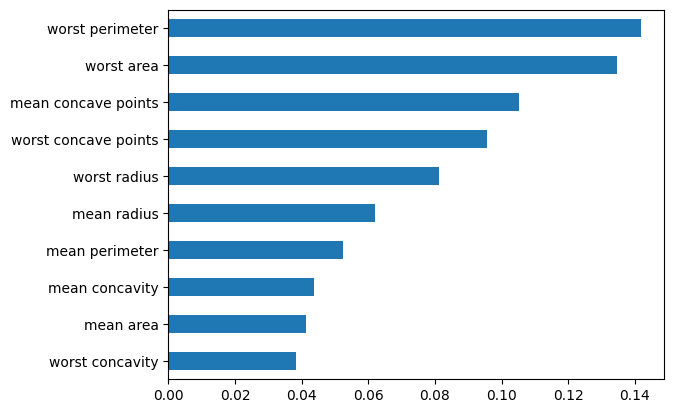

Vraie réponse : 1
Le modèle dit cancer à : 0.93
(5000, 30)

--- Étape 3 : distances des 4 premières voisines ---
[0.   5.35 6.   5.05]

--- Étape 4 : poids des 4 premières voisines ---
[1.    0.429 0.344 0.469]

--- Étape 5 : les 10 mesures choisies ---
['worst perimeter', 'worst radius', 'worst area', 'fractal dimension error', 'mean concave points', 'worst smoothness', 'worst concave points', 'worst concavity', 'mean radius', 'mean concavity']

--- Étape 7 : l'explication LIME de la tumeur 1 ---
R² : 0.508
worst area                 0.0434
worst concavity            0.0372
worst radius               0.0370
worst perimeter            0.0306
worst concave points       0.0252
worst smoothness           0.0206
mean concave points        0.0152
mean radius                0.0085
fractal dimension error   -0.0082
mean concavity             0.0069
dtype: float64


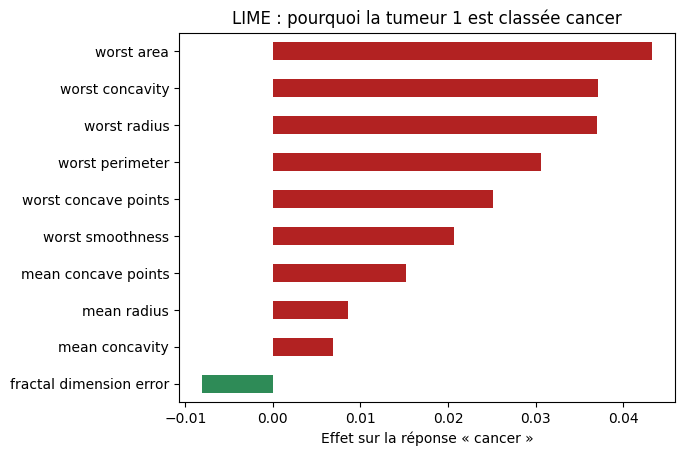

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done

--- Comparaison : LIME officiel ---
R² officiel : 0.496
worst concavity 0.0417
worst area 0.039
worst radius 0.0358
worst perimeter 0.0303
worst concave points 0.025
worst smoothness 0.0168
mean concave points 0.0128
mean radius 0.0096
fractal dimension error -0.0058
compactness error -0.0032

--- Limite 1 : 5 tirages différents ---
Tirage 0 | R² = 0.508 | top 3 : ['worst area', 'worst concavity', 'worst radius']
Tirage 1 | R² = 0.486 | top 3 : ['worst area', 'worst concavity', 'worst radius']
Tirage 2 | R² = 0.501 | top 3 : ['worst area', 'worst concavity', 'worst radius']
Tirage 3 | R² = 0.495 | top 3 : ['worst area', 'worst concavity', 'worst radius']
Tirage 4 | R² = 0.497 | top 3 : ['worst area', 'worst concavity', 'worst radius']

--- Limite 2 : largeur du noyau ---
Largeur x 0.25 | R² = 0.044 | top 3 : ['worst concave points', 'worst area', 'worst radius']
La

In [13]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

donnees = load_breast_cancer()
X = donnees.data
y = 1 - donnees.target
noms = list(donnees.feature_names)
print(X.shape)
print("Cancers :", y.sum(), "| Pas cancer :", (y == 0).sum())


tableau = pd.DataFrame(X, columns=noms)
tableau.head()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print("Apprentissage :", X_train.shape, "| Test :", X_test.shape)
print("Cancers dans le test :", y_test.sum())

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)

pred = rf.predict(X_test)
vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
print("Cancers trouvés :", vp)
print("Cancers ratés   :", fn)
print("Fausses alertes :", fp)
print("Bien reconnues  :", vn)
print("Bonnes réponses :", round((vp + vn) / len(y_test) * 100, 1), "%")


proba = rf.predict_proba(X_test)[:, 1]
for seuil in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred_seuil = (proba >= seuil).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred_seuil).ravel()
    print("Seuil", seuil, "-> cancers ratés :", fn, "| fausses alertes :", fp)



    importances = pd.Series(rf.feature_importances_, index=noms).sort_values(ascending=False)
print(importances.head(10).round(3))
importances.head(10).sort_values().plot.barh()
plt.show()


x = X_test[0]
print("Vraie réponse :", y_test[0])
print("Le modèle dit cancer à :", rf.predict_proba([x])[0, 1])


hasard = np.random.default_rng(0)
moyenne = X_train.mean(axis=0)
ecart = X_train.std(axis=0)

Z = x + hasard.normal(size=(5000, 30)) * ecart
Z[0] = x
print(Z.shape)

# ===== Calcul de y_voisins (correction) =====
y_voisins = rf.predict_proba(Z)[:, 1]
# ===== Étape 2 : demander au modèle =====
y_voisins = rf.predict_proba(Z)[:, 1]

# ===== Étape 3 : la distance =====
Z_std = (Z - moyenne) / ecart
distances = np.linalg.norm(Z_std - Z_std[0], axis=1)
print("\n--- Étape 3 : distances des 4 premières voisines ---")
print(distances[:4].round(2))

# ===== Étape 4 : les poids =====
largeur = 0.75 * np.sqrt(30)
poids = np.sqrt(np.exp(-distances**2 / largeur**2))
print("\n--- Étape 4 : poids des 4 premières voisines ---")
print(poids[:4].round(3))

# ===== Étape 5 : choisir les 10 mesures =====
from sklearn.linear_model import Ridge
tri = Ridge(alpha=0.01).fit(Z_std, y_voisins, sample_weight=poids)
choisies = np.argsort(-np.abs(tri.coef_ * Z_std[0]))[:10]
print("\n--- Étape 5 : les 10 mesures choisies ---")
print([str(noms[j]) for j in choisies])

# ===== Étape 6 : le petit modèle simple =====
local = Ridge(alpha=1.0).fit(Z_std[:, choisies], y_voisins, sample_weight=poids)

# ===== Étape 7 : lire le résultat =====
r2 = local.score(Z_std[:, choisies], y_voisins, sample_weight=poids)
explication = pd.Series(local.coef_, index=[str(noms[j]) for j in choisies])
explication = explication.sort_values(key=abs, ascending=False)
print("\n--- Étape 7 : l'explication LIME de la tumeur 1 ---")
print("R² :", round(r2, 3))
print(explication.round(4))

# ===== Graphique de l'explication =====
expl_triee = explication.sort_values()
couleurs = ["firebrick" if v > 0 else "seagreen" for v in expl_triee]
expl_triee.plot.barh(color=couleurs)
plt.title("LIME : pourquoi la tumeur 1 est classée cancer")
plt.xlabel("Effet sur la réponse « cancer »")
plt.show()

# ===== Comparaison avec la bibliothèque officielle =====
!pip install -q lime
from lime.lime_tabular import LimeTabularExplainer
officiel = LimeTabularExplainer(X_train, feature_names=[str(n) for n in noms],
                                discretize_continuous=False, sample_around_instance=True,
                                random_state=0)
exp = officiel.explain_instance(x, rf.predict_proba, labels=(1,), num_features=10, num_samples=5000)
print("\n--- Comparaison : LIME officiel ---")
print("R² officiel :", round(exp.score, 3))
for nom, coef in exp.as_list(label=1):
    print(nom, round(coef, 4))

# ===== Tout LIME dans une fonction =====
def lime_maison(x, graine=0, largeur=0.75 * np.sqrt(30)):
    hasard = np.random.default_rng(graine)
    Z = x + hasard.normal(size=(5000, 30)) * ecart
    Z[0] = x
    y_voisins = rf.predict_proba(Z)[:, 1]
    Z_std = (Z - moyenne) / ecart
    distances = np.linalg.norm(Z_std - Z_std[0], axis=1)
    poids = np.sqrt(np.exp(-distances**2 / largeur**2))
    tri = Ridge(alpha=0.01).fit(Z_std, y_voisins, sample_weight=poids)
    choisies = np.argsort(-np.abs(tri.coef_ * Z_std[0]))[:10]
    local = Ridge(alpha=1.0).fit(Z_std[:, choisies], y_voisins, sample_weight=poids)
    r2 = local.score(Z_std[:, choisies], y_voisins, sample_weight=poids)
    explication = pd.Series(local.coef_, index=[str(noms[j]) for j in choisies])
    return explication.sort_values(key=abs, ascending=False), r2

# ===== Limite 1 : l'instabilité =====
print("\n--- Limite 1 : 5 tirages différents ---")
for graine in range(5):
    e, s = lime_maison(x, graine=graine)
    print("Tirage", graine, "| R² =", round(s, 3), "| top 3 :", list(e.index[:3]))

# ===== Limite 2 : la largeur du noyau =====
print("\n--- Limite 2 : largeur du noyau ---")
for facteur in [0.25, 1, 4]:
    e, s = lime_maison(x, largeur=facteur * 0.75 * np.sqrt(30))
    print("Largeur x", facteur, "| R² =", round(s, 3), "| top 3 :", list(e.index[:3]))